In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

In [2]:
df=pd.read_excel("/Users/HP/OneDrive/Desktop/GERD/Data/GERD_PSS.xlsx")

In [3]:
df.head()

,IndexNo,HeartBurn1,DisabilityHB,HBorNot,HBfrequency,Reflux2,DisabilityReflux,RefluxOrNot,RefluxFrequency,ChestPain3,...,StressAmount2,antiglycemicnew,antihypertensivenew,skipbreakfastnew,inadequatesleepnew,currentsmkernew,frequentalcoholnew,COFFEEINTAKEPERMONTH,BELOWOLEVEL,incomelessthan50000
0,1,2,2,1,1,1,1,2,0,1,...,1,1,0,0,0,1,0,1,0,0
1,2,1,1,2,0,1,1,2,0,2,...,1,0,0,0,1,0,0,1,1,0
2,3,3,3,1,2,1,1,2,0,3,...,2,1,1,0,1,0,0,1,1,1
3,4,1,1,2,0,1,1,2,0,1,...,1,1,1,0,0,0,0,0,0,1
4,5,1,1,2,0,1,1,2,0,1,...,2,0,0,0,1,0,0,0,0,0


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
IndexNo,1200.0,600.500000,346.554469,1.0,300.75,600.5,900.25,1200.0
HeartBurn1,1200.0,1.735000,1.227204,1.0,1.00,1.0,2.00,5.0
DisabilityHB,1200.0,1.485000,0.867219,1.0,1.00,1.0,2.00,4.0
HBorNot,1200.0,1.664167,0.472478,1.0,1.00,2.0,2.00,2.0
HBfrequency,1200.0,0.607500,0.954395,0.0,0.00,0.0,1.00,3.0
...,...,...,...,...,...,...,...,...
currentsmkernew,1200.0,0.185000,0.388459,0.0,0.00,0.0,0.00,1.0
frequentalcoholnew,1200.0,0.041667,0.199910,0.0,0.00,0.0,0.00,1.0
COFFEEINTAKEPERMONTH,1200.0,0.356667,0.479215,0.0,0.00,0.0,1.00,1.0
BELOWOLEVEL,1200.0,0.550833,0.497617,0.0,0.00,1.0,1.00,1.0


In [5]:
df.columns

Index(['IndexNo', 'HeartBurn1', 'DisabilityHB', 'HBorNot', 'HBfrequency',
       'Reflux2', 'DisabilityReflux', 'RefluxOrNot', 'RefluxFrequency',
       'ChestPain3', 'DisailityCP', 'CPorNot', 'CPfrequency', 'AbdFullness',
       'DisabilityAF', 'BloatingOrNot4', 'BloatingFrequency', 'Dysphagia',
       'DisabilityDysphagia', 'DysphagiaOrNot', 'DysphagiaFrequency', 'Cough',
       'DisabilityCough', 'CoughOrNot', 'CoughFrequency', 'Burping',
       'DisabilityBurp', 'BurpingOrNot', 'BurpingFrequency', 'GORDscore',
       'GORDgrade', 'GORDorNOT', 'GORDclassification', 'Age', 'AgeCategory',
       'Gender', 'Maritalstatus', 'Medication', 'Relief', 'PPI',
       'Antiglycemics', 'Antihypertensives', 'DM', 'SkipBreakfast',
       'EnoughSleep', 'Smoking', 'Smoking2', 'FrequentAlcoholUse',
       'SymIncWithStress', 'AbdCircumference', 'AbdObesityAsian',
       'AbdObesityWHO', 'HipCircumference', 'WaistToHipRatio',
       'AbdObesity@WHratio', 'PhysicalActivity', 'AdequatePhyAct', 'PSSsco

In [6]:
df.shape

(1200, 69)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 69 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   IndexNo               1200 non-null   int64  
 1   HeartBurn1            1200 non-null   int64  
 2   DisabilityHB          1200 non-null   int64  
 3   HBorNot               1200 non-null   int64  
 4   HBfrequency           1200 non-null   int64  
 5   Reflux2               1200 non-null   int64  
 6   DisabilityReflux      1200 non-null   int64  
 7   RefluxOrNot           1200 non-null   int64  
 8   RefluxFrequency       1200 non-null   int64  
 9   ChestPain3            1200 non-null   int64  
 10  DisailityCP           1200 non-null   int64  
 11  CPorNot               1200 non-null   int64  
 12  CPfrequency           1200 non-null   int64  
 13  AbdFullness           1200 non-null   int64  
 14  DisabilityAF          1200 non-null   int64  
 15  BloatingOrNot4       

In [8]:
df.corr()[["GORDorNOT"]].sort_values(by="GORDorNOT")

,GORDorNOT
GORDclassification,-0.827736
HBfrequency,-0.820092
HeartBurn1,-0.816224
RefluxFrequency,-0.673040
Reflux2,-0.669130
...,...
Medication,0.379012
BloatingOrNot4,0.389947
RefluxOrNot,0.564542
HBorNot,0.669032


In [9]:
# Assuming df is your DataFrame
correlations = df.corr()["GORDorNOT"].sort_values()

# Filter for strong correlations (absolute value greater than a threshold, e.g., 0.5)
strong_correlations = correlations[abs(correlations) > 0.5]

# Display the result
print(strong_correlations)

GORDclassification   -0.827736
HBfrequency          -0.820092
HeartBurn1           -0.816224
RefluxFrequency      -0.673040
Reflux2              -0.669130
GORDscore            -0.666143
GORDgrade            -0.659542
DisabilityHB         -0.631188
DisabilityReflux     -0.520341
RefluxOrNot           0.564542
HBorNot               0.669032
GORDorNOT             1.000000
Name: GORDorNOT, dtype: float64


In [10]:
import pandas as pd

# Assuming your DataFrame is named df
# Replace df with your actual DataFrame name

# Calculate the correlation matrix
correlation_matrix = df.corr()

# Filter for strong and positive correlations with "GORDorNOT"
strong_positive_corr = correlation_matrix["GORDorNOT"].sort_values(ascending=False).loc[lambda x: x > 0]

print(strong_positive_corr)


GORDorNOT               1.000000
HBorNot                 0.669032
RefluxOrNot             0.564542
BloatingOrNot4          0.389947
Medication              0.379012
PPI                     0.349372
BurpingOrNot            0.348635
CPorNot                 0.343653
CoughOrNot              0.171492
DysphagiaOrNot          0.163132
SkipBreakfast           0.138362
EnoughSleep             0.126131
Antiglycemics           0.066236
Antihypertensives       0.063995
AdequatePhyAct          0.061521
Smoking2                0.053095
DM                      0.048929
AbdObesityAsian         0.041674
FrequentAlcoholUse      0.041551
AbdObesityWHO           0.033511
Maritalstatus           0.029996
COFFEEINTAKEPERMONTH    0.029707
AbdObesity@WHratio      0.026230
AgeCategory             0.023597
Age                     0.013088
IndexNo                 0.008761
BELOWOLEVEL             0.005598
Name: GORDorNOT, dtype: float64


In [11]:
import pandas as pd

# Assuming your DataFrame is named df
# Replace df with your actual DataFrame name

# Calculate the correlation matrix
correlation_matrix = df.corr()

# Filter for strong and positive correlations with "GORDorNOT"
strong_positive_corr = correlation_matrix["PSSscore"].sort_values(ascending=False).loc[lambda x: x > 0]

print(strong_positive_corr)


PSSscore               1.000000
StressLevel            0.844666
StressAmount2          0.818015
GORDscore              0.241982
GORDclassification     0.213387
DisabilityReflux       0.206061
GORDgrade              0.202625
DisailityCP            0.176444
HBfrequency            0.172228
ChestPain3             0.168809
DisabilityBurp         0.168189
HeartBurn1             0.168123
CPfrequency            0.167887
DisabilityHB           0.167149
RefluxFrequency        0.163045
Reflux2                0.154453
BurpingFrequency       0.154141
Cough                  0.153414
Maritalstatus          0.151881
CoughFrequency         0.150290
Burping                0.149674
DisabilityAF           0.147723
skipbreakfastnew       0.137655
DisabilityCough        0.136117
BloatingFrequency      0.123416
AbdFullness            0.114829
DisabilityDysphagia    0.097655
SymIncWithStress       0.085185
AbdObesityWHO          0.077207
DysphagiaFrequency     0.074432
Dysphagia              0.072205
Relief  

In [12]:
import pandas as pd

# Assuming your DataFrame is named df
# Replace df with your actual DataFrame name

# Calculate the correlation matrix
correlation_matrix = df.corr()

# Filter for strong and positive correlations with "GORDorNOT"
strong_positive_corr = correlation_matrix["GORDclassification"].sort_values(ascending=False).loc[lambda x: x > 0]

print(strong_positive_corr)


GORDclassification     1.000000
HBfrequency            0.750155
SymIncWithStress       0.732305
HeartBurn1             0.731095
GORDgrade              0.679687
GORDscore              0.614087
RefluxFrequency        0.611590
DisabilityHB           0.608467
Reflux2                0.596704
Relief                 0.566880
DisabilityReflux       0.497692
BloatingFrequency      0.459675
AbdFullness            0.452749
CPfrequency            0.393586
BurpingFrequency       0.385639
ChestPain3             0.384263
DisabilityAF           0.382903
Burping                0.381938
DisailityCP            0.355775
DisabilityBurp         0.247194
PSSscore               0.213387
CoughFrequency         0.204521
Cough                  0.201972
DisabilityCough        0.185441
DisabilityDysphagia    0.166689
StressAmount2          0.162663
skipbreakfastnew       0.162187
StressLevel            0.162180
inadequatesleepnew     0.156816
DysphagiaFrequency     0.147646
Dysphagia              0.146967
antihype

In [13]:
import pandas as pd

# Assuming your DataFrame is named df
# Replace df with your actual DataFrame name

# Calculate the correlation matrix
correlation_matrix = df.corr()

# Filter for strong and positive correlations with "GORDorNOT"
strong_positive_corr = correlation_matrix["GORDclassification"].sort_values(ascending=False).loc[lambda x: x > 0.5]

print(strong_positive_corr)


GORDclassification    1.000000
HBfrequency           0.750155
SymIncWithStress      0.732305
HeartBurn1            0.731095
GORDgrade             0.679687
GORDscore             0.614087
RefluxFrequency       0.611590
DisabilityHB          0.608467
Reflux2               0.596704
Relief                0.566880
Name: GORDclassification, dtype: float64


In [14]:
# Extract the column names with strong and positive correlations
selected_columns = strong_positive_corr.index.tolist()

In [15]:
# Create a new DataFrame with selected columns
df_selected = df[selected_columns]

In [16]:
df_selected.head()

,GORDclassification,HBfrequency,SymIncWithStress,HeartBurn1,GORDgrade,GORDscore,RefluxFrequency,DisabilityHB,Reflux2,Relief
0,2,1,2,2,1,10,0,2,1,0
1,2,0,2,1,2,14,0,1,1,1
2,3,2,1,3,2,34,0,3,1,2
3,1,0,0,1,1,7,0,1,1,0
4,1,0,0,1,1,7,0,1,1,0


In [17]:
y=df['GORDclassification']
X=df.drop(['GORDclassification'],axis=1)

In [18]:
categories = df['GORDclassification'].unique()
print("Unique Categories:", categories)


Unique Categories: [2 3 1]


In [19]:
# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=38)


In [20]:
# Scaling the data (recommended for logistic regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [21]:
# Initializing and training the Multiple Logistic Regression model with OneVsRestClassifier
model = OneVsRestClassifier(LogisticRegression(solver='liblinear'))
model.fit(X_train_scaled, y_train)

OneVsRestClassifier(estimator=LogisticRegression(solver='liblinear'))

In [22]:
# Get decision function scores
y_scores = model.decision_function(X_test_scaled)


In [23]:
# Making predictions on the test set
y_pred = model.predict(X_test_scaled)

In [24]:
# Evaluating the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)


In [25]:
print(f"Accuracy: {accuracy}")
print("Confusion Matrix:")
print(conf_matrix)

Accuracy: 1.0
Confusion Matrix:
[[124   0   0]
 [  0 144   0]
 [  0   0  92]]


In [26]:
# Calculate precision, recall, and F1 score
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')

In [27]:
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")


Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [28]:
from sklearn.metrics import classification_report

# Assuming y_test and y_pred are already defined
print(classification_report(y_test, y_pred, target_names=[f'Class {c}' for c in categories]))


              precision    recall  f1-score   support

     Class 2       1.00      1.00      1.00       124
     Class 3       1.00      1.00      1.00       144
     Class 1       1.00      1.00      1.00        92

    accuracy                           1.00       360
   macro avg       1.00      1.00      1.00       360
weighted avg       1.00      1.00      1.00       360



In [29]:
# Binarize the labels for ROC curve
y_test_bin = label_binarize(y_test, classes=np.unique(y))

In [30]:
# Get decision function scores
y_scores = model.decision_function(X_test_scaled)


In [31]:
# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(y_test_bin.shape[1]):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_scores[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])


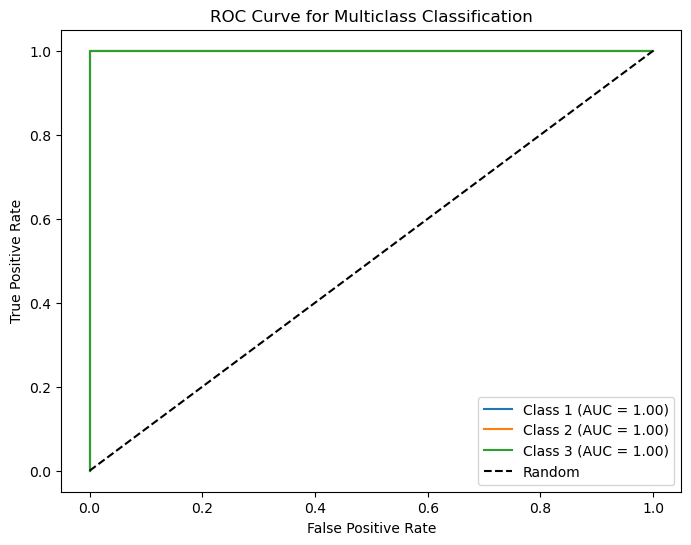

In [32]:
# Plot ROC curves
plt.figure(figsize=(8, 6))

for i in range(y_test_bin.shape[1]):
    plt.plot(fpr[i], tpr[i], label=f'Class {np.unique(y)[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multiclass Classification')
plt.legend(loc='lower right')
plt.show()

SVM

In [33]:
# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=32)


In [34]:
from sklearn.svm import SVC
# Scaling the data (recommended for SVM)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [35]:
# Initializing and training the Support Vector Machine model
model = OneVsRestClassifier(SVC(kernel='linear', probability=True))  # Use 'linear' kernel for better interpretability
model.fit(X_train_scaled, y_train)

OneVsRestClassifier(estimator=SVC(kernel='linear', probability=True))

In [36]:
# Making predictions on the test set
y_pred = model.predict(X_test_scaled)

In [37]:
# Evaluating the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)


In [38]:
print(f"Accuracy: {accuracy}")
print("Confusion Matrix:")
print(conf_matrix)


Accuracy: 1.0
Confusion Matrix:
[[81  0  0]
 [ 0 99  0]
 [ 0  0 60]]


In [39]:
# Calculate precision, recall, and F1 Score
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')


In [40]:
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [41]:
# Binarize the labels for ROC curve
y_test_bin = label_binarize(y_test, classes=np.unique(y))

# Get decision function scores
y_scores = model.decision_function(X_test_scaled)

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(y_test_bin.shape[1]):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_scores[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])


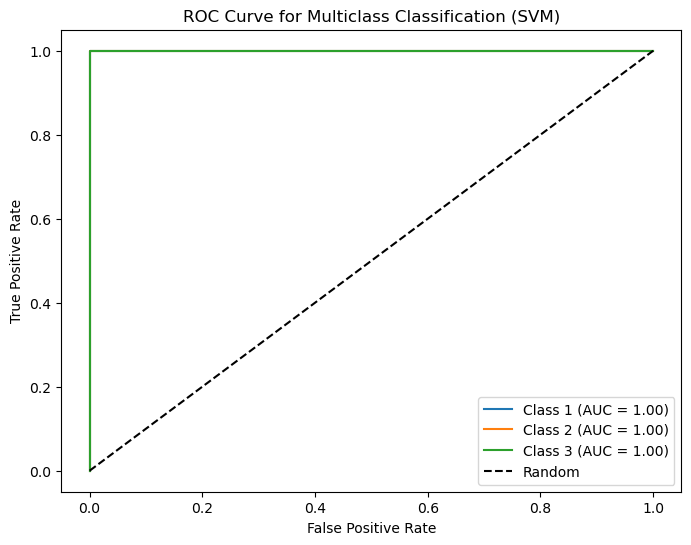

In [42]:
# Plot ROC curves
plt.figure(figsize=(8, 6))

for i in range(y_test_bin.shape[1]):
    plt.plot(fpr[i], tpr[i], label=f'Class {np.unique(y)[i]} (AUC = {roc_auc[i]:.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Multiclass Classification (SVM)')
plt.legend(loc='lower right')
plt.show()

In [59]:
from keras.models import Sequential
from keras.layers import Dense
from keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.layers import Dropout


In [60]:
# Convert labels to numerical values
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)


In [61]:
# Convert numerical labels to one-hot encoding
y_one_hot = to_categorical(y_encoded)


In [62]:
# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_one_hot, test_size=0.2, random_state=32)


In [63]:
# Scaling the data (recommended for neural networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [64]:
# Define the ANN model
model = Sequential()
model.add(Dense(units=128, activation='relu', input_shape=(X_train_scaled.shape[1],)))  # Use Input(shape) instead of input_shape
model.add(Dropout(0.5))  # Add dropout for regularization
model.add(Dense(units=64, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(units=32, activation='relu'))
model.add(Dense(units=len(label_encoder.classes_), activation='softmax'))


C:\Users\HP\anaconda3\lib\site-packages\keras\src\layers\core\dense.py:73: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [65]:
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])


In [66]:
# Train the model and store the history
history = model.fit(X_train_scaled, y_train, epochs=20, batch_size=32, validation_split=0.2, verbose=1)


Epoch 1/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.3382 - loss: 1.3331 - val_accuracy: 0.6771 - val_loss: 0.9029
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5973 - loss: 0.9072 - val_accuracy: 0.7292 - val_loss: 0.6994
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6152 - loss: 0.7820 - val_accuracy: 0.8073 - val_loss: 0.5353
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7526 - loss: 0.5854 - val_accuracy: 0.8229 - val_loss: 0.4344
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8169 - loss: 0.4756 - val_accuracy: 0.8646 - val_loss: 0.3180
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8303 - loss: 0.3820 - val_accuracy: 0.9010 - val_loss: 0.2378
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8742 - loss: 0.3270 - val_accuracy: 0.9427 - val_loss: 0.1816
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8900 - loss: 0.2595 - val_accuracy: 0.9583 - val_loss

In [67]:
# Evaluate the model on the test set
y_pred_prob = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)

# Convert predicted labels back to original class labels
y_pred_labels = label_encoder.inverse_transform(y_pred)

# Convert true labels back to original class labels
y_true_labels = label_encoder.inverse_transform(np.argmax(y_test, axis=1))

# Evaluating the model
accuracy = accuracy_score(y_true_labels, y_pred_labels)
conf_matrix = confusion_matrix(y_true_labels, y_pred_labels)

print(f"Accuracy: {accuracy}")
print("Confusion Matrix:")
print(conf_matrix)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
Accuracy: 0.9791666666666666
Confusion Matrix:
[[80  1  0]
 [ 4 95  0]
 [ 0  0 60]]


In [68]:
# Calculate precision, recall, and F1 Score
precision = precision_score(y_true_labels, y_pred_labels, average='weighted')
recall = recall_score(y_true_labels, y_pred_labels, average='weighted')
f1 = f1_score(y_true_labels, y_pred_labels, average='weighted')

print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Precision: 0.9796316964285714
Recall: 0.9791666666666666
F1 Score: 0.9791958041958042


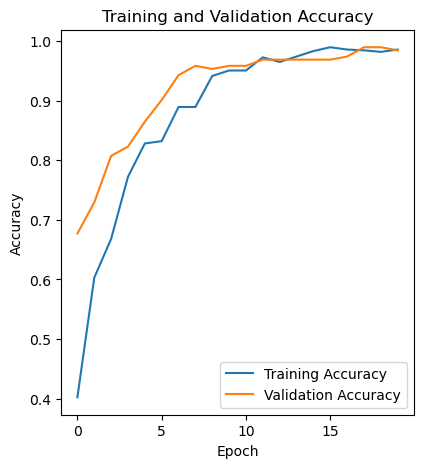

In [69]:
# Visualize training and validation accuracy over epochs
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


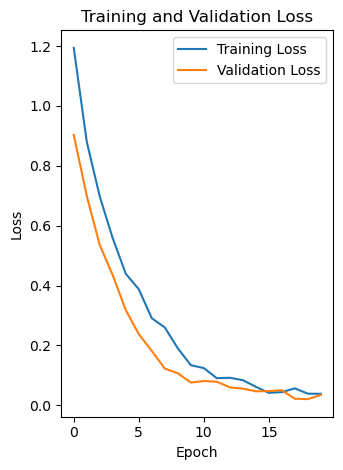

In [70]:
# Visualize training and validation loss over epochs
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

Epoch 1/20


C:\Users\HP\anaconda3\lib\site-packages\keras\src\layers\core\dense.py:73: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.3271 - loss: 1.1970 - val_accuracy: 0.6771 - val_loss: 0.8357
Epoch 2/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6108 - loss: 0.8656 - val_accuracy: 0.7396 - val_loss: 0.7087
Epoch 3/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6943 - loss: 0.7177 - val_accuracy: 0.8073 - val_loss: 0.5252
Epoch 4/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7548 - loss: 0.5808 - val_accuracy: 0.8542 - val_loss: 0.4500
Epoch 5/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8338 - loss: 0.4225 - val_accuracy: 0.8854 - val_loss: 0.3014
Epoch 6/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8655 - loss: 0.3557 - val_accuracy: 0.9115 - val_loss: 0.2464
Epoch 7/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8827 - loss: 0.2930 - val_accuracy: 0.9479 - val_loss: 0.1661
Epoch 8/20
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9252 - loss: 0.2200 - val_accuracy: 0.9531 - val_loss: 0.1108
Ep

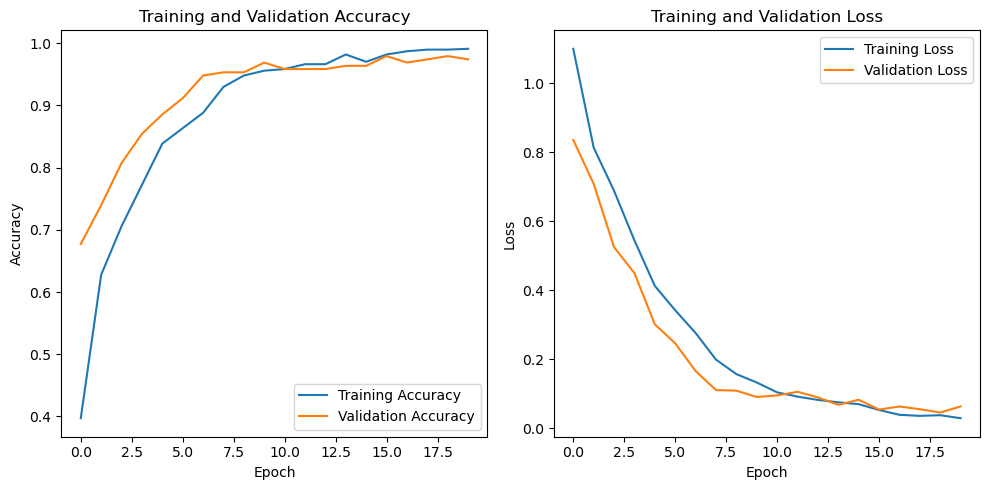

In [71]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score
from sklearn.preprocessing import label_binarize
from keras.models import Sequential
from keras.layers import Dense, Dropout
from keras.utils import to_categorical

# Assuming df is your DataFrame
y = df['GORDclassification']
X = df.drop(['GORDclassification'], axis=1)

# Convert labels to numerical values
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Convert numerical labels to one-hot encoding
y_one_hot = to_categorical(y_encoded)

# Splitting the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y_one_hot, test_size=0.2, random_state=32)

# Scaling the data (recommended for neural networks)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Define the ANN model
model = Sequential()
model.add(Dense(units=128, activation='relu', input_dim=X_train_scaled.shape[1]))
model.add(Dropout(0.5))  # Add dropout for regularization
model.add(Dense(units=64, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(units=32, activation='relu'))
model.add(Dense(units=len(label_encoder.classes_), activation='softmax'))

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model and get the history directly
history = model.fit(X_train_scaled, y_train, epochs=20, batch_size=32, validation_split=0.2, verbose=1)

# Evaluate the model on the test set
y_pred_prob = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)

# Convert predicted labels back to original class labels
y_pred_labels = label_encoder.inverse_transform(y_pred)

# Convert true labels back to original class labels
y_true_labels = label_encoder.inverse_transform(np.argmax(y_test, axis=1))

# Evaluating the model
accuracy = accuracy_score(y_true_labels, y_pred_labels)
conf_matrix = confusion_matrix(y_true_labels, y_pred_labels)

print(f"Accuracy: {accuracy}")
print("Confusion Matrix:")
print(conf_matrix)

# Calculate precision, recall, and F1 Score
precision = precision_score(y_true_labels, y_pred_labels, average='weighted')
recall = recall_score(y_true_labels, y_pred_labels, average='weighted')
f1 = f1_score(y_true_labels, y_pred_labels, average='weighted')

print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

# Visualize training and validation accuracy over epochs
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Visualize training and validation loss over epochs
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()
